In [1]:
# Shim: notebook tidak punya __file__.
import os
__file__ = os.path.abspath("keras_iris.ipynb")

# # Praktikum 2 — Keras pada Dataset Iris
#
# Arsitektur modul: Dense(10, relu) -> Dense(8, relu) -> Dense(3, softmax),
# optimizer adam, loss categorical_crossentropy.
# Seed dipatok (`tf.keras.utils.set_random_seed(42)`, `random_state=42`).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from pathlib import Path
from sklearn.datasets import load_iris
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

HERE = Path(__file__).resolve().parent
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
import keras
print("tf", tf.__version__, "| keras", keras.__version__)

tf 2.15.1 | keras 2.15.0


# ## 1. Data
#
# **Perbaikan dari modul:** `OneHotEncoder(sparse=False)` sudah dihapus di scikit-learn 1.2+,
# diganti `sparse_output=False` (atau `tf.keras.utils.to_categorical`).

In [3]:
iris = load_iris()
X, y = iris.data, iris.target.reshape(-1, 1)

encoder = OneHotEncoder(sparse_output=False)   # modul: sparse=False -> TypeError di sklearn 1.7
y = encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED)     # modul tanpa random_state -> tidak reproducible
print("latih:", X_train.shape, "uji:", X_test.shape)

latih: (120, 4) uji: (30, 4)


# ## 2. Model dasar modul (10-8-3, relu, adam, 50 epoch, batch 8)

loss uji: 0.207368 | akurasi uji: 0.9667



classification_report (uji):
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        10
  versicolor     1.0000    0.8889    0.9412         9
   virginica     0.9167    1.0000    0.9565        11

    accuracy                         0.9667        30
   macro avg     0.9722    0.9630    0.9659        30
weighted avg     0.9694    0.9667    0.9664        30



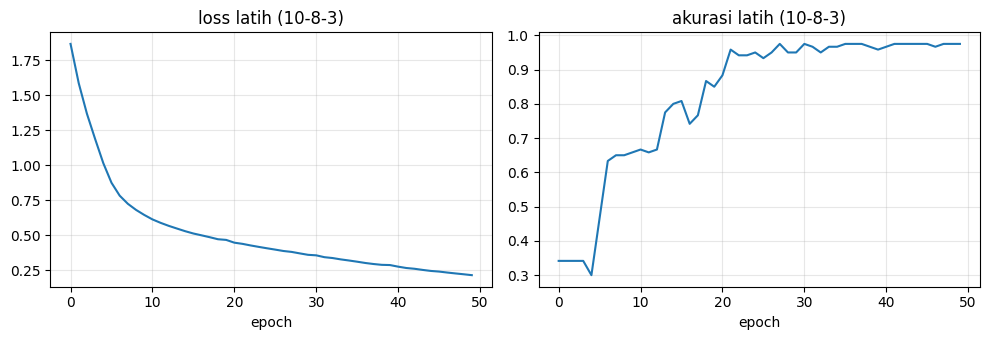

In [4]:
def buat_model(hidden=(10, 8), act="relu", n_out=3, n_in=4):
    layers = [tf.keras.Input(shape=(n_in,))]
    for h in hidden:
        layers.append(tf.keras.layers.Dense(h, activation=act))
    layers.append(tf.keras.layers.Dense(n_out, activation="softmax"))
    m = tf.keras.Sequential(layers)
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m


tf.keras.utils.set_random_seed(SEED)
model = buat_model()
h = model.fit(X_train, y_train, epochs=50, batch_size=8, verbose=0)
loss, acc = model.evaluate(X_test, y_test, verbose=0)
print(f"loss uji: {loss:.6f} | akurasi uji: {acc:.4f}")

y_pred = model.predict(X_test, verbose=0).argmax(1)
print("\nclassification_report (uji):")
print(classification_report(y_test.argmax(1), y_pred,
                            target_names=iris.target_names, digits=4, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(h.history["loss"]); ax[0].set_title("loss latih (10-8-3)")
ax[0].set_xlabel("epoch"); ax[0].grid(alpha=.3)
ax[1].plot(h.history["accuracy"]); ax[1].set_title("akurasi latih (10-8-3)")
ax[1].set_xlabel("epoch"); ax[1].grid(alpha=.3)
fig.tight_layout(); fig.savefig(OUT / "01_kurva_model_dasar.png", dpi=120)

# ## 3. Tugas 2 — variasi jumlah neuron hidden layer

    konfigurasi       hidden aktifasi  loss_uji  akurasi_uji  akurasi_latih  loss_latih
       4 (relu)         (4,)     relu  0.370778     0.933333       0.925000    0.358333
       8 (relu)         (8,)     relu  0.362597     0.966667       0.975000    0.371445
    10-8 (relu)      (10, 8)     relu  0.207368     0.966667       0.975000    0.214676
   16-16 (relu)     (16, 16)     relu  0.175362     1.000000       0.975000    0.164736
   32-16 (relu)     (32, 16)     relu  0.092813     1.000000       0.966667    0.093537
64-32-16 (relu) (64, 32, 16)     relu  0.068819     0.966667       0.966667    0.071546


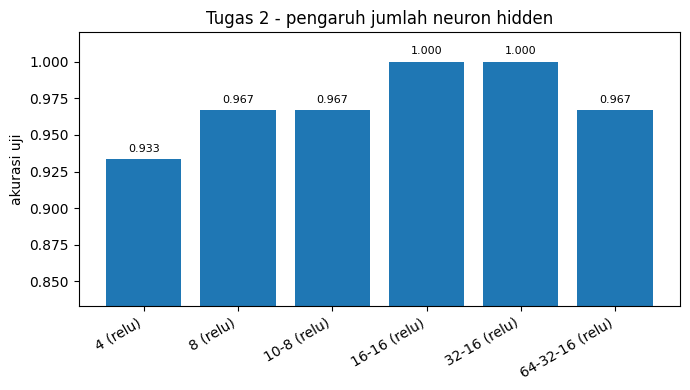

In [5]:
def jalankan(hidden, act="relu", epochs=50, batch=8):
    tf.keras.utils.set_random_seed(SEED)
    m = buat_model(hidden=hidden, act=act)
    hist = m.fit(X_train, y_train, epochs=epochs, batch_size=batch, verbose=0)
    l, a = m.evaluate(X_test, y_test, verbose=0)
    return dict(konfigurasi="-".join(map(str, hidden)) + f" ({act})",
                hidden=str(hidden), aktifasi=act,
                loss_uji=l, akurasi_uji=a,
                akurasi_latih=hist.history["accuracy"][-1],
                loss_latih=hist.history["loss"][-1]), hist


baris = []
for hidden in [(4,), (8,), (10, 8), (16, 16), (32, 16), (64, 32, 16)]:
    r, _ = jalankan(hidden)
    baris.append(r)
df = pd.DataFrame(baris)
print(df.to_string(index=False, float_format=lambda v: f"{v:.6f}"))
df.to_csv(OUT / "hasil_variasi_neuron.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(df["konfigurasi"], df["akurasi_uji"])
ax.set_ylim(max(0, df["akurasi_uji"].min() - 0.1), 1.02)
ax.set_ylabel("akurasi uji"); ax.set_title("Tugas 2 - pengaruh jumlah neuron hidden")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
for i, v in enumerate(df["akurasi_uji"]):
    ax.text(i, v + .005, f"{v:.3f}", ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "02_variasi_neuron.png", dpi=120)

# ## 4. Tugas 3 — Sigmoid vs ReLU (loss dan akurasi)

In [6]:
baris = []
for act in ("sigmoid", "relu"):
    for hidden in [(8,), (10, 8), (16, 16)]:
        r, hist = jalankan(hidden, act=act)
        r["akurasi_epoch_10"] = hist.history["accuracy"][9]
        baris.append(r)
df_act = pd.DataFrame(baris)
print(df_act[["konfigurasi", "loss_latih", "akurasi_latih",
              "akurasi_epoch_10", "loss_uji", "akurasi_uji"]]
      .to_string(index=False, float_format=lambda v: f"{v:.6f}"))
df_act.to_csv(OUT / "hasil_sigmoid_vs_relu.csv", index=False)

    konfigurasi  loss_latih  akurasi_latih  akurasi_epoch_10  loss_uji  akurasi_uji
    8 (sigmoid)    0.532430       0.966667          0.708333  0.526920     1.000000
 10-8 (sigmoid)    0.581847       0.825000          0.366667  0.572326     0.800000
16-16 (sigmoid)    0.395612       0.966667          0.891667  0.378696     0.966667
       8 (relu)    0.371445       0.975000          0.858333  0.362597     0.966667
    10-8 (relu)    0.214676       0.975000          0.658333  0.207368     0.966667
   16-16 (relu)    0.164736       0.975000          0.658333  0.175362     1.000000


# Sigmoid pada hidden layer memperlambat konvergensi (gradien jenuh), ReLU lebih cepat
# mencapai akurasi tinggi pada epoch yang sama.

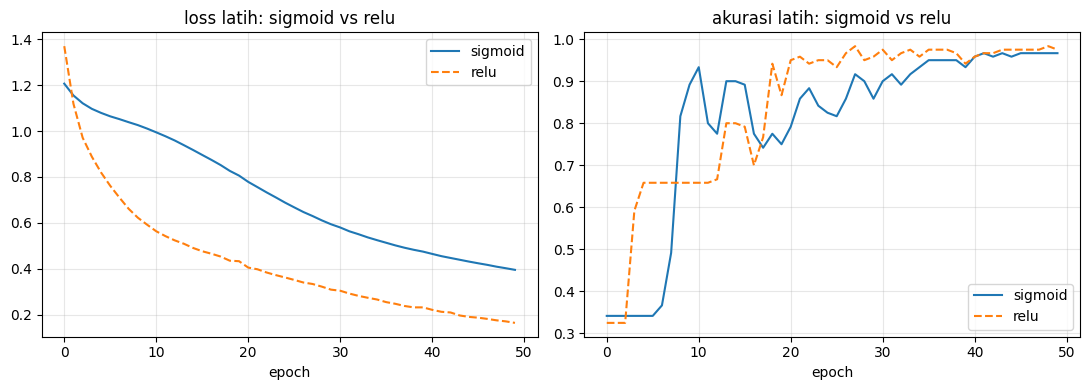

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for act, style in (("sigmoid", "-"), ("relu", "--")):
    _, hist = jalankan((16, 16), act=act)
    ax[0].plot(hist.history["loss"], style, label=act)
    ax[1].plot(hist.history["accuracy"], style, label=act)
ax[0].set_title("loss latih: sigmoid vs relu"); ax[0].set_xlabel("epoch"); ax[0].grid(alpha=.3)
ax[1].set_title("akurasi latih: sigmoid vs relu"); ax[1].set_xlabel("epoch"); ax[1].grid(alpha=.3)
ax[0].legend(); ax[1].legend()
fig.tight_layout(); fig.savefig(OUT / "03_sigmoid_vs_relu.png", dpi=120)

In [8]:
ringkas = df_act.groupby("aktifasi").agg(loss_uji_rata2=("loss_uji", "mean"),
                                     akurasi_uji_rata2=("akurasi_uji", "mean"),
                                     akurasi_ep10_rata2=("akurasi_epoch_10", "mean"))
print("Rekap per aktivasi (3 arsitektur):")
print(ringkas.to_string(float_format=lambda v: f"{v:.6f}"))

Rekap per aktivasi (3 arsitektur):
          loss_uji_rata2  akurasi_uji_rata2  akurasi_ep10_rata2
aktifasi                                                       
relu            0.248443           0.977778            0.725000
sigmoid         0.492647           0.922222            0.655556
